# 실험 1단계 — 정제만 한 데이터로 바로 학습 (베이스라인)

기상 조인·특성공학·하이퍼파라미터 튜닝·불균형 처리를 **하나도 하지 않은** 상태의 성능을 잰다. 다음 단계(기상 조인 등)가 성능을 올리는지 비교하는 기준점이다. 실험 계획은 `EXP/1/readme.md`.

| 항목 | 내용 |
|---|---|
| 입력 | `data/X.parquet`, `data/y.parquet` (`EXP/1/1_데이터정제.ipynb` 에서 저장) |
| 분할 | 기준일 `mnfctur_de` 로 시간순 — train ~2024-06-30 · val 2024-07-01~2025-06-30 · test 2025-07-01~2026-06-30(고정) |
| 모델 | XGBoost, LightGBM, CatBoost — 라이브러리 기본 하이퍼파라미터, seed 만 고정 |
| 학습 장치 | XGBoost GPU · LightGBM CPU · CatBoost CPU (2절 `DEVICE` 에서 바꿈) |
| 불균형 처리 | 하지 않음 (`scale_pos_weight`·가중치·샘플링 없음) |
| 조기 종료 | 하지 않음 — 트리 수는 기본값 고정(XGBoost·LightGBM 100개, CatBoost 1,000개) |
| val 의 쓰임 | 임계값을 고르는 데만 쓴다 (학습·조기 종료에 쓰지 않음) |
| 임계값 | 0.5 · val 에서 F1 최대 · val 에서 F2 최대 — 세 가지 결과를 모두 기록 |
| 기록 지표 | 임계값, accuracy, precision, recall, f1, f2, roc_auc, pr_auc, 혼동행렬(TP·FN·FP·TN), 전체 건수 |
| 결과 기록 | MLflow 실험 `리스테리아_EXP1` 의 run `2_바로학습` (10절). 파일로 따로 저장하지 않는다 |

> LSTM 은 이 노트북에서 돌리지 않는다. 입력이 시료당 한 줄짜리 칼럼(품목·주소 출처·좌표 등)뿐이라 LSTM 에 넣을 시간 순서 입력이 없다. 기상 D-1~D-100 을 붙이는 2단계에서 다룬다.

## 1. 데이터 불러오기

- `X` 7열 = 행 키 `lims_data_key` + 기준일 `mnfctur_de` + 모델 피처 5개(`src_route`·`prdlst_code`·`train_prdlst_code`·`date_basis`·`addr_source`, 모두 범주형) (2026-10-01: 검사기관 코드 `inspct_instt_code` 제거, 로마자로 적힌 한국 주소 78행의 `src_route` 를 domestic 으로, `lat`·`lon`·`legal_dong_code`·`train_prdlst_nm` 제거, `train_prdlst_code` 결측 170행 → `'기타'` — `1_데이터정제.ipynb`)
- `y` 파일 = 행 키 `lims_data_key` + 타깃 `judge_result` (검출 1, 불검출 0). `lims_data_key` 로 X 의 행 순서에 맞춘 뒤 `judge_result` 한 칼럼만 1차원(Series)으로 쓴다.

In [1]:
import pandas as pd

X_path = r"C:\Users\NT751\Desktop\천영진\리스테리아ML\data\X.parquet"
y_path = r"C:\Users\NT751\Desktop\천영진\리스테리아ML\data\y.parquet"

X = pd.read_parquet(X_path)
y_df = pd.read_parquet(y_path)   # lims_data_key + judge_result

# y 를 행 키 lims_data_key 로 X 의 행 순서에 맞춘 뒤, 타깃 judge_result 한 칼럼(Series)만 쓴다
assert y_df['lims_data_key'].is_unique, 'y 의 lims_data_key 가 중복됨'
y = (y_df.set_index('lims_data_key')['judge_result']
         .reindex(X['lims_data_key'])
         .set_axis(X.index))
assert y.notna().all(), 'X 의 lims_data_key 중 y 에 없는 행이 있음'

print('X', X.shape, '| y', y.shape, '| 검출', int(y.sum()))

X (676537, 11) | y (676537,) | 검출 1969


In [2]:
X

,lims_data_key,src_route,prdlst_code,train_prdlst_code,train_prdlst_nm,mnfctur_de,date_basis,addr_source,legal_dong_code,lat,lon
0,O000001_160100103_5_4,domestic,Z3800100000000,Z3800000000000,기타기준규격외,2016-03-11,의뢰일,제조사소재지,4113310500,37.433239,127.164383
1,O000001_160100300_4_4,domestic,Z3800100000000,Z3800000000000,기타기준규격외,2016-03-22,의뢰일,제조사소재지,4122025300,36.986122,126.931168
2,O000033_170101151_1_5,domestic,Z2700400000000,Z2700000000000,"정액,수정란,종란",2017-02-22,제조일,업소주소,5279043000,35.514168,126.674095
3,O000027_170101235_2_7,domestic,Z3800100000000,Z3800000000000,기타기준규격외,2017-01-20,제조일,업소주소,2917012800,35.209167,126.879715
4,1471142_170100097_1_1092137,domestic,B01010100F1000,B0100000000000,축산물,2017-03-07,제조일,제조사소재지,5218012100,35.595753,126.869698
...,...,...,...,...,...,...,...,...,...,...,...
676532,1471124_170704332_1_11,overseas,C0201110200000,C0318000000000,유가공품류,2017-07-19,선적일,해외제조업소,NaN,-38.395367,142.627716
676533,O000024_160103149_1_5,domestic,C0121020000000,C0312000000000,조미식품,2016-06-08,의뢰일,인허가대장,5221011800,35.774906,126.917442
676534,O000024_160105715_1_4,domestic,C0123020000000,C0313000000000,절임류 또는 조림류,2016-08-30,제조일,인허가대장,4888040000,35.710964,128.014709
676535,O000031_170700207_1_5,domestic,C0201180100000,C0318000000000,유가공품류,2017-03-29,제조일,인허가대장,4377035000,37.018387,127.495041


## 2. 실험 설정

라이브러리, seed, 학습 장치, 분할 날짜, MLflow 기록 위치를 이 셀 하나에 모은다. 값을 바꿀 때는 여기만 고친다.

- **학습 장치(`DEVICE`)**: XGBoost 는 GPU(RTX 2060, `'cuda'`), LightGBM 은 CPU(설치된 판에 GPU 기능이 없음), CatBoost 는 CPU(`'CPU'`).
- CatBoost 를 CPU 로 둔 이유: GPU 로 돌리면 같은 seed 여도 매번 결과가 달라져(5-3) 비교 기준으로 쓸 수 없다. 대신 학습이 약 45초 → 약 164초로 늘어난다.
- 같은 seed 로 다시 돌리면 XGBoost·LightGBM·CatBoost(CPU) 모두 같은 결과가 나온다.
- 다음 단계와 성능을 비교할 때는 장치 설정도 같게 둔다(CatBoost 는 GPU·CPU 기본값이 다르다).
- **MLflow**: `.env` 에서 `AFLA_MLFLOW_URI` 키 하나만 읽는다(DB 접속 정보는 읽지 않음). 기록 위치·구조는 10절 참고.

In [3]:
import json
import logging
import sys
import tempfile
import time
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter
import sklearn
import xgboost as xgb
import lightgbm as lgb
import catboost as cb
import os
os.environ.setdefault('MLFLOW_DISABLE_AGENT_HINT', '1')   # mlflow 가 찍는 LLM 추적 안내 문구 끄기
import mlflow
from dotenv import dotenv_values
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
    roc_auc_score, average_precision_score, confusion_matrix, precision_recall_curve,
)

SEED = 42

# 학습 장치 — 모델마다 따로 정한다
DEVICE = {
    'XGBoost': 'cuda',   # GPU. 'cpu' 로 바꿔도 된다 — 어느 쪽이든 다시 돌리면 같은 결과
    'LightGBM': 'cpu',   # 설치된 LightGBM 은 GPU 기능이 없는 판
    'CatBoost': 'CPU',   # 'GPU' 는 빠르지만 다시 돌릴 때마다 결과가 달라진다(5-3). 같은 결과가 필요하면 'CPU'
}

# 분할 날짜 — mnfctur_de 기준, 양 끝 날짜 포함
TRAIN_END = '2024-06-30'
VAL_START, VAL_END = '2024-07-01', '2025-06-30'
TEST_START, TEST_END = '2025-07-01', '2026-06-30'   # readme 고정 기간

KEY_COL = 'lims_data_key'   # 행 키 — 피처에서 제외
DATE_COL = 'mnfctur_de'     # 분할 기준 — 피처에서 제외

# MLflow — 결과는 파일로 따로 저장하지 않고 전부 여기에 기록한다 (10절)
ENV_PATH = Path(r'C:\Users\NT751\Desktop\천영진\리스테리아ML\.env')
PROJECT_DIR = ENV_PATH.parent                         # 리스테리아ML/
MLFLOW_URI = dotenv_values(ENV_PATH).get('AFLA_MLFLOW_URI')   # .env 에서 이 키 하나만 읽는다
assert MLFLOW_URI, '.env 에 AFLA_MLFLOW_URI 가 없음'
if MLFLOW_URI.startswith('sqlite:///') and not Path(MLFLOW_URI.removeprefix('sqlite:///')).is_absolute():
    # 상대경로면 노트북을 연 폴더마다 DB 가 따로 생긴다 → .env 가 있는 리스테리아ML/ 기준으로 고정
    MLFLOW_URI = 'sqlite:///' + (PROJECT_DIR / MLFLOW_URI.removeprefix('sqlite:///')).as_posix()
MLFLOW_ARTIFACTS = PROJECT_DIR / 'mlruns'             # 그림·표·예측 파일이 쌓이는 곳
MLFLOW_EXPERIMENT = '리스테리아_EXP1'                  # EXP/1 노트북들이 함께 쓰는 실험
RUN_NAME = '2_바로학습'                                # 이 노트북의 run 이름

logging.getLogger('alembic').setLevel(logging.WARNING)   # DB 처음 만들 때의 안내 로그 숨김
mlflow.set_tracking_uri(MLFLOW_URI)
if mlflow.get_experiment_by_name(MLFLOW_EXPERIMENT) is None:
    mlflow.create_experiment(MLFLOW_EXPERIMENT, artifact_location=MLFLOW_ARTIFACTS.as_uri())
mlflow.set_experiment(MLFLOW_EXPERIMENT)

plt.rcParams['font.family'] = 'Malgun Gothic'   # 그림 속 한글
plt.rcParams['axes.unicode_minus'] = False

print('장치:', DEVICE)
print('MLflow:', MLFLOW_URI, '| 실험', MLFLOW_EXPERIMENT)
print('xgboost', xgb.__version__, '| lightgbm', lgb.__version__, '| catboost', cb.__version__,
      '| scikit-learn', sklearn.__version__, '| mlflow', mlflow.__version__)

2026/10/01 17:07:58 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/01 17:07:58 INFO mlflow.store.db.utils: Updating database tables


장치: {'XGBoost': 'cuda', 'LightGBM': 'cpu', 'CatBoost': 'CPU'}
MLflow: sqlite:///C:/Users/NT751/Desktop/천영진/리스테리아ML/mlflow.db | 실험 리스테리아_EXP1
xgboost 3.4.1 | lightgbm 4.7.0 | catboost 1.2.10 | scikit-learn 1.9.1 | mlflow 3.16.1


## 3. 데이터 분할 (시간순)

기준일 `mnfctur_de` 로 나눈다. 랜덤 분할은 쓰지 않는다 — 미래 시료가 학습에 섞이면 성능이 실제보다 좋게 나온다.

| 구간 | 기간 | 쓰임 |
|---|---|---|
| train | 2015-04-07 ~ 2024-06-30 | 모델 학습 |
| val | 2024-07-01 ~ 2025-06-30 | 임계값 고르기 (학습에는 안 씀) |
| test | 2025-07-01 ~ 2026-06-30 | 최종 성능. 임계값을 고를 때 보지 않는다 |

튜닝을 하지 않으므로 val 은 임계값을 정하는 데만 쓴다. 임계값을 정한 뒤에도 train+val 로 다시 학습하지 않고, train 으로 학습한 모델 그대로 test 를 평가한다.

In [4]:
assert len(X) == len(y) and X.index.equals(y.index), 'X 와 y 의 행이 맞지 않음'

d = X[DATE_COL]
masks = {
    'train': d <= pd.Timestamp(TRAIN_END),
    'val':   d.between(pd.Timestamp(VAL_START), pd.Timestamp(VAL_END)),
    'test':  d.between(pd.Timestamp(TEST_START), pd.Timestamp(TEST_END)),
}

# 한 행이 두 구간에 겹쳐 들어가지 않았는지, 어느 구간에도 안 들어간 행이 있는지 확인
n_assigned = sum(m.astype(int) for m in masks.values())
assert n_assigned.max() == 1, '두 구간에 겹치는 행이 있음'
print('어느 구간에도 속하지 않는 행:', int((n_assigned == 0).sum()))

split_summary = pd.DataFrame([
    {'구간': s, '시작일': d[m].min().date(), '종료일': d[m].max().date(),
     '행 수': int(m.sum()), '검출(1)': int(y[m].sum()),
     '검출 비율(%)': round(y[m].mean() * 100, 3)}
    for s, m in masks.items()
])
display(split_summary)

assert (split_summary['검출(1)'] > 0).all(), '검출이 0건인 구간이 있음 — precision·recall 을 계산할 수 없음'

어느 구간에도 속하지 않는 행: 0


,구간,시작일,종료일,행 수,검출(1),검출 비율(%)
0,train,2015-04-07,2024-06-30,497896,1491,0.299
1,val,2024-07-01,2025-06-30,87553,191,0.218
2,test,2025-07-01,2026-06-30,91088,287,0.315


## 4. 모델 입력 준비

- **피처**: `lims_data_key`(행 키)와 `mnfctur_de`(분할 기준)를 뺀 9개. 새 변수는 만들지 않는다.
- **결측**: 채우지 않는다. XGBoost·LightGBM 은 NaN 을 그대로 받는다.
- **범주형 칼럼**(category 형식)은 모델마다 받는 방식이 달라 입력 형식만 맞춘다.
  - XGBoost: `enable_categorical=True` 를 켜면 category 형식을 그대로 받는다.
  - LightGBM: category 형식을 그대로 받는다.
  - CatBoost: 범주형 칼럼에 NaN 을 받지 못한다. 그래서 CatBoost 에 넣을 때만 범주형 칼럼을 문자열로 바꾸고, 결측은 `'NaN'` 이라는 값 하나로 넣는다. 모델 입력 형식을 맞추는 것이고 `X.parquet` 는 바뀌지 않는다.

In [5]:
FEATURES = [c for c in X.columns if c not in (KEY_COL, DATE_COL)]
CAT_COLS = X[FEATURES].select_dtypes('category').columns.tolist()
NUM_COLS = [c for c in FEATURES if c not in CAT_COLS]

print(f'피처 {len(FEATURES)}개')
print(f'  범주형 {len(CAT_COLS)}개:', CAT_COLS)
print(f'  수치형 {len(NUM_COLS)}개:', NUM_COLS)
print('결측이 있는 피처(행 수):', X[FEATURES].isna().sum().loc[lambda s: s > 0].to_dict())

피처 9개
  범주형 7개: ['src_route', 'prdlst_code', 'train_prdlst_code', 'train_prdlst_nm', 'date_basis', 'addr_source', 'legal_dong_code']
  수치형 2개: ['lat', 'lon']
결측이 있는 피처(행 수): {'train_prdlst_code': 170, 'legal_dong_code': 47642}


In [6]:
def to_catboost_input(df):
    """CatBoost 입력용 복사본 — 범주형 칼럼을 문자열로, 결측은 'NaN' 값으로"""
    out = df.copy()
    for c in CAT_COLS:
        out[c] = out[c].astype(object).where(out[c].notna(), 'NaN').astype(str)
    return out

SPLITS = ['train', 'val', 'test']
Xs = {s: X.loc[masks[s], FEATURES] for s in SPLITS}      # XGBoost·LightGBM 용
Xs_cb = {s: to_catboost_input(Xs[s]) for s in SPLITS}    # CatBoost 용
ys = {s: y[masks[s]] for s in SPLITS}

for s in SPLITS:
    print(f'{s:5s}  X {Xs[s].shape}  y {ys[s].shape}  검출 {int(ys[s].sum()):,}')

train  X (497896, 9)  y (497896,)  검출 1,491
val    X (87553, 9)  y (87553,)  검출 191
test   X (91088, 9)  y (91088,)  검출 287


## 5. 모델 학습 — 기본 하이퍼파라미터

- 튜닝하지 않는다. 각 라이브러리의 기본값을 그대로 쓰고, 같은 결과가 다시 나오도록 seed 만 고정한다.
- 불균형 보정(`scale_pos_weight`, `class_weight`, 샘플링)을 하지 않는다.
- val 을 보고 학습을 멈추는 조기 종료(early stopping)도 하지 않는다.
- 모델을 만들 때 넣는 인자는 튜닝 값이 아니다: 범주형 지정(`enable_categorical`, `cat_features`), 장치(`device`, `task_type`), 로그·파일 끄기(`verbose`, `allow_writing_files`), seed.
- 각 셀은 학습 시간과 실제로 쓰인 트리 수·깊이·학습률을 찍는다. 하이퍼파라미터 전체는 10절에서 MLflow 에 기록한다.

In [7]:
models = {}        # 모델 이름 → 학습된 모델
fit_seconds = {}   # 모델 이름 → 학습 시간(초)

def model_input(name, split):
    """모델별 입력 — CatBoost 만 문자열 변환본을 쓴다"""
    return Xs_cb[split] if name == 'CatBoost' else Xs[split]

def key_params(name, model):
    """학습에 실제로 쓰인 트리 수·깊이·학습률"""
    if name == 'XGBoost':
        tp = json.loads(model.get_booster().save_config())['learner']['gradient_booster']['tree_train_param']
        return {'트리 수': model.get_booster().num_boosted_rounds(),
                '최대 깊이': int(tp['max_depth']), '학습률': round(float(tp['eta']), 4)}
    if name == 'LightGBM':
        p = model.get_params()
        return {'트리 수': p['n_estimators'], '잎 수': p['num_leaves'], '학습률': p['learning_rate']}
    p = model.get_all_params()
    return {'트리 수': p['iterations'], '깊이': p['depth'], '학습률': round(p['learning_rate'], 4)}

def fit_model(name, model):
    t0 = time.perf_counter()
    model.fit(model_input(name, 'train'), ys['train'])
    models[name] = model
    fit_seconds[name] = round(time.perf_counter() - t0, 1)
    print(f'{name} 학습 완료 — {fit_seconds[name]}초, 장치 {DEVICE[name]}, {key_params(name, model)}')

### 5-1. XGBoost

`enable_categorical=True` 로 category 칼럼을 그대로 받는다. 기본값은 트리 100개, 최대 깊이 6, 학습률 0.3.

In [8]:
fit_model('XGBoost', xgb.XGBClassifier(
    enable_categorical=True,
    device=DEVICE['XGBoost'],
    random_state=SEED,
))

XGBoost 학습 완료 — 1.4초, 장치 cuda, {'트리 수': 100, '최대 깊이': 6, '학습률': 0.3}


### 5-2. LightGBM

category 칼럼을 자동으로 범주형으로 쓴다. 기본값은 트리 100개, 잎 31개, 학습률 0.1. 설치된 LightGBM 은 GPU 기능 없이 빌드된 판이라 CPU 로 학습한다.

In [9]:
fit_model('LightGBM', lgb.LGBMClassifier(
    random_state=SEED,
    verbose=-1,
))

LightGBM 학습 완료 — 0.9초, 장치 cpu, {'트리 수': 100, '잎 수': 31, '학습률': 0.1}


### 5-3. CatBoost

`cat_features` 로 범주형 칼럼을 지정한다. 기본값은 트리 1,000개, 깊이 6이고 학습률은 데이터 크기와 장치를 보고 자동으로 정한다. 세 모델 중 가장 오래 걸린다(이 데이터에서 GPU 약 45초, CPU 약 164초).

- **GPU 로 학습하면 같은 seed 로 다시 돌려도 결과가 달라진다.** 2026-09-28 이 노트북 코드를 GPU 로 두 번 돌렸을 때 val 에서 고른 임계값이 F1최대 0.148 → 0.161, F2최대 0.070 → 0.054 로 바뀌었고, test 에서 F2최대 recall 이 4.9% → 7.7%, roc_auc 가 0.772 → 0.777 로 달라졌다. CPU 는 연습용 데이터로 두 번 돌렸을 때 결과가 완전히 같았다.
- GPU 와 CPU 는 기본값도 다르다. 이 데이터에서 자동으로 정해진 학습률이 GPU 0.024, CPU 0.146 이고, 수치형 칼럼을 나누는 구간 수 `border_count` 도 GPU 128, CPU 254 다. 그래서 장치를 바꾸면 결과도 달라진다.
- `allow_writing_files=False`: 학습 로그 폴더(`catboost_info/`)를 만들지 않는다.
- GPU 로 학습하는 동안 GPU 메모리를 거의 다 쓴다(6GB 중 약 5.8GB). 다른 노트북에서 GPU 작업을 동시에 돌리지 않는다.

In [10]:
fit_model('CatBoost', cb.CatBoostClassifier(
    cat_features=CAT_COLS,
    task_type=DEVICE['CatBoost'],
    random_seed=SEED,
    verbose=200,
    allow_writing_files=False,
))

Learning rate set to 0.146087


0:	learn: 0.3606143	total: 252ms	remaining: 4m 11s


200:	learn: 0.0150854	total: 29.4s	remaining: 1m 56s


400:	learn: 0.0143722	total: 1m	remaining: 1m 30s


600:	learn: 0.0138332	total: 1m 30s	remaining: 1m


800:	learn: 0.0134046	total: 2m	remaining: 29.8s


999:	learn: 0.0130918	total: 2m 30s	remaining: 0us


CatBoost 학습 완료 — 152.0초, 장치 CPU, {'트리 수': 1000, '깊이': 6, '학습률': 0.1461}


## 6. val·test 확률 예측

train 으로 학습한 모델 하나로 val 과 test 를 모두 예측한다. 값은 각 시료가 검출(1)일 확률(0~1)이다.

GPU 로 학습한 XGBoost 에 CPU 메모리의 표를 넣으면 "mismatched devices" 경고가 뜬다. 예측값은 같고 속도만 조금 느려지는 것이라 이 경고만 숨긴다.

In [11]:
warnings.filterwarnings('ignore', message='.*Falling back to prediction using DMatrix')

proba = {s: pd.DataFrame(index=Xs[s].index) for s in ['val', 'test']}
for name, model in models.items():
    for s in ['val', 'test']:
        proba[s][name] = model.predict_proba(model_input(name, s))[:, 1]

print('test 예측 확률 분포')
display(proba['test'].describe(percentiles=[0.5, 0.9, 0.99, 0.999]).T)

test 예측 확률 분포


,count,mean,std,min,50%,90%,99%,99.9%,max
XGBoost,91088.0,0.003072,0.017219,3.006636e-39,0.000043,0.004373,0.044932,0.225152,1.000000
LightGBM,91088.0,0.003940,0.018894,1.393910e-188,0.000094,0.004372,0.113573,0.152662,0.712823
CatBoost,91088.0,0.002607,0.011204,6.247634e-07,0.000805,0.004532,0.023279,0.130825,0.416484


## 7. 임계값 정하기 — val 에서만

예측 확률이 임계값 **이상**이면 검출(1)로 판정한다. 아래 세 임계값의 결과를 모두 기록한다.

| 규칙 | 정하는 방법 | 뜻 |
|---|---|---|
| `0.5` | 고정 | 라이브러리 기본 판정 기준. 비교용 |
| `F1최대` | val 에서 F1 이 가장 큰 임계값 | precision 과 recall 을 같은 무게로 본다 |
| `F2최대` | val 에서 F2 가 가장 큰 임계값 | recall 을 precision 보다 무겁게 본다. 식품안전은 검출을 놓치는 비용이 커서 함께 기록한다 |

- Fβ = (1+β²) × precision × recall / (β² × precision + recall). β=1 이면 F1, β=2 이면 F2.
- 후보 임계값은 val 예측 확률에 나온 서로 다른 값 전부다(`precision_recall_curve`). 그중 Fβ 가 가장 큰 값을 고른다.
- test 는 이 단계에서 보지 않는다. test 로 임계값을 고르면 정답을 보고 기준을 맞춘 셈이라 성능이 부풀려진다.

In [12]:
def fbeta_curve(precision, recall, beta):
    b2 = beta ** 2
    denom = b2 * precision + recall
    return np.divide((1 + b2) * precision * recall, denom,
                     out=np.zeros_like(denom, dtype=float), where=denom > 0)

def best_threshold(y_true, p, beta):
    """Fβ 가 가장 큰 임계값과 그때의 Fβ (판정: p >= 임계값)"""
    precision, recall, thr = precision_recall_curve(y_true, p)
    f = fbeta_curve(precision[:-1], recall[:-1], beta)   # 마지막 점은 짝이 되는 임계값이 없어 제외
    i = int(np.argmax(f))
    return float(thr[i]), float(f[i])

thresholds = {}   # 모델 → {규칙: 임계값}
rows = []
for name in models:
    t_f1, f1_val = best_threshold(ys['val'], proba['val'][name], beta=1)
    t_f2, f2_val = best_threshold(ys['val'], proba['val'][name], beta=2)
    thresholds[name] = {'0.5': 0.5, 'F1최대': t_f1, 'F2최대': t_f2}
    rows.append({'모델': name, 'F1최대 임계값': t_f1, 'val F1': f1_val,
                 'F2최대 임계값': t_f2, 'val F2': f2_val})

display(pd.DataFrame(rows).round({'F1최대 임계값': 6, 'val F1': 4, 'F2최대 임계값': 6, 'val F2': 4}))

,모델,F1최대 임계값,val F1,F2최대 임계값,val F2
0,XGBoost,0.132155,0.0793,0.097485,0.0857
1,LightGBM,0.135741,0.0842,0.123407,0.0718
2,CatBoost,0.047964,0.0468,0.011759,0.0807


## 8. 평가 — 임계값 규칙별 지표

모델 3개 × 임계값 규칙 3개 × 구간 2개(val·test) = 18줄을 계산한다. **최종 성능은 test** 다. val 은 임계값을 고른 구간이라 test 보다 좋게 나오는 것이 보통이며 참고용이다.

지표 읽는 법
- **accuracy**: 검출이 0.3% 뿐이라 전부 불검출로 찍어도 약 99.7% 가 나온다. 참고로만 본다.
- **precision**: 검출로 판정한 것 중 실제 검출 비율. **recall**: 실제 검출 중 잡아낸 비율.
- **roc_auc·pr_auc**: 임계값과 상관없이 확률의 순서만 본다. 그래서 같은 모델·구간이면 세 규칙에서 값이 같다. pr_auc 는 `average_precision_score`(평균 정밀도)로 계산했고, 아무렇게나 찍을 때의 기대값은 검출 비율(약 0.3%)이다.
- **혼동행렬**: TP = 검출을 검출로 판정, FN = 검출을 놓침, FP = 불검출을 검출로 잘못 판정, TN = 불검출을 불검출로 판정.
- **예측 양성 수** = TP + FP. 검출로 판정되어 확인이 필요한 시료 수다.

In [13]:
def evaluate(y_true, p, threshold):
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        '임계값': threshold,
        '전체 건수': len(y_true),
        '실제 검출': int(y_true.sum()),
        '예측 양성 수': int(tp + fp),
        'accuracy': accuracy_score(y_true, pred),
        'precision': precision_score(y_true, pred, zero_division=0),
        'recall': recall_score(y_true, pred, zero_division=0),
        'f1': f1_score(y_true, pred, zero_division=0),
        'f2': fbeta_score(y_true, pred, beta=2, zero_division=0),
        'roc_auc': roc_auc_score(y_true, p),
        'pr_auc': average_precision_score(y_true, p),
        'TP': int(tp), 'FN': int(fn), 'FP': int(fp), 'TN': int(tn),
    }

records = []
for name in models:
    for rule, t in thresholds[name].items():
        for s in ['val', 'test']:
            records.append({'모델': name, '구간': s, '임계값 규칙': rule,
                            **evaluate(ys[s], proba[s][name], t)})
metrics = pd.DataFrame(records)

SCORE_COLS = ['accuracy', 'precision', 'recall', 'f1', 'f2', 'roc_auc', 'pr_auc']

def show_metrics(split):
    df = metrics[metrics['구간'] == split].drop(columns='구간').reset_index(drop=True)
    display(df.round({**{c: 4 for c in SCORE_COLS}, '임계값': 6}))

### 8-1. test — 최종 성능 (2025-07-01 ~ 2026-06-30)

In [14]:
show_metrics('test')

,모델,임계값 규칙,임계값,전체 건수,실제 검출,예측 양성 수,accuracy,precision,recall,f1,f2,roc_auc,pr_auc,TP,FN,FP,TN
0,XGBoost,0.5,0.500000,91088,287,18,0.9967,0.0000,0.0000,0.0000,0.0000,0.7236,0.0102,0,287,18,90783
1,XGBoost,F1최대,0.132155,91088,287,131,0.9956,0.0763,0.0348,0.0478,0.0391,0.7236,0.0102,10,277,121,90680
2,XGBoost,F2최대,0.097485,91088,287,569,0.9909,0.0264,0.0523,0.0350,0.0437,0.7236,0.0102,15,272,554,90247
3,LightGBM,0.5,0.500000,91088,287,13,0.9968,0.1538,0.0070,0.0133,0.0086,0.7651,0.0145,2,285,11,90790
4,LightGBM,F1최대,0.135741,91088,287,124,0.9958,0.0968,0.0418,0.0584,0.0472,0.7651,0.0145,12,275,112,90689
5,LightGBM,F2최대,0.123407,91088,287,423,0.9925,0.0284,0.0418,0.0338,0.0382,0.7651,0.0145,12,275,411,90390
6,CatBoost,0.5,0.500000,91088,287,0,0.9968,0.0000,0.0000,0.0000,0.0000,0.7551,0.0132,0,287,0,90801
7,CatBoost,F1최대,0.047964,91088,287,518,0.9914,0.0232,0.0418,0.0298,0.0360,0.7551,0.0132,12,275,506,90295
8,CatBoost,F2최대,0.011759,91088,287,2466,0.9712,0.0260,0.2230,0.0465,0.0885,0.7551,0.0132,64,223,2402,88399


### 8-2. val — 참고 (임계값을 고른 구간)

In [15]:
show_metrics('val')

,모델,임계값 규칙,임계값,전체 건수,실제 검출,예측 양성 수,accuracy,precision,recall,f1,f2,roc_auc,pr_auc,TP,FN,FP,TN
0,XGBoost,0.5,0.500000,87553,191,15,0.9977,0.1333,0.0105,0.0194,0.0128,0.8217,0.0205,2,189,13,87349
1,XGBoost,F1최대,0.132155,87553,191,137,0.9966,0.0949,0.0681,0.0793,0.0721,0.8217,0.0205,13,178,124,87238
2,XGBoost,F2최대,0.097485,87553,191,811,0.9892,0.0333,0.1414,0.0539,0.0857,0.8217,0.0205,27,164,784,86578
3,LightGBM,0.5,0.500000,87553,191,12,0.9977,0.1667,0.0105,0.0197,0.0129,0.8364,0.0248,2,189,10,87352
4,LightGBM,F1최대,0.135741,87553,191,94,0.9970,0.1277,0.0628,0.0842,0.0699,0.8364,0.0248,12,179,82,87280
5,LightGBM,F2최대,0.123407,87553,191,629,0.9911,0.0318,0.1047,0.0488,0.0718,0.8364,0.0248,20,171,609,86753
6,CatBoost,0.5,0.500000,87553,191,7,0.9978,0.2857,0.0105,0.0202,0.0130,0.8201,0.0219,2,189,5,87357
7,CatBoost,F1최대,0.047964,87553,191,749,0.9898,0.0294,0.1152,0.0468,0.0727,0.8201,0.0219,22,169,727,86635
8,CatBoost,F2최대,0.011759,87553,191,2580,0.9696,0.0209,0.2827,0.0390,0.0807,0.8201,0.0219,54,137,2526,84836


## 9. 그림

1. **val 임계값별 지표** (모델별 한 줄, 위 칸 precision·recall / 아래 칸 F1·F2) — 임계값을 바꾸면 지표가 어떻게 움직이는지, 고른 임계값이 어디인지 본다. 세로 점선이 val 에서 고른 임계값(F1·F2)과 0.5 이고, 점은 F1·F2 곡선의 최고점이다.
2. **test PR 곡선** — 세 모델의 precision–recall 균형을 한 번에 비교한다. 동그라미·세모는 val 에서 고른 임계값이 test 에서 찍힌 자리다. 회색 가로선은 아무렇게나 찍을 때의 기준(검출 비율)이다.

- 두 그림 모두 **로그 눈금**을 쓴다(1번은 가로축 임계값, 2번은 세로축 precision). 예측 확률이 대부분 0.01 아래에 몰려 있고(6절 분포) precision 도 1% 안팎이라, 보통 눈금으로 그리면 곡선이 한쪽 구석에 붙어 읽을 수 없다.
- 두 그림 모두 10절에서 MLflow 에 올린다(파일로 따로 저장하지 않음).

In [16]:
# 그림 공통 색·선
SURFACE, INK, INK2, MUTED, GRID, AXIS = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
MODEL_COLOR = {'XGBoost': '#2a78d6', 'LightGBM': '#eb6834', 'CatBoost': '#1baf7a'}
METRIC_COLOR = {'precision': '#2a78d6', 'recall': '#eb6834', 'F1': '#1baf7a', 'F2': '#eda100'}
PLAIN = FuncFormatter(lambda v, _: f'{v:g}')   # 로그 눈금 숫자를 0.001·0.01·0.1·1 로 표시
FIGURES = {}   # 파일 이름 → 그림. 10절에서 MLflow 에 올린다

def style_axes(ax):
    ax.set_facecolor(SURFACE)
    ax.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color(AXIS)
    ax.tick_params(colors=AXIS, labelcolor=INK2, labelsize=9)

### 9-1. val — 임계값에 따른 precision·recall·F1·F2

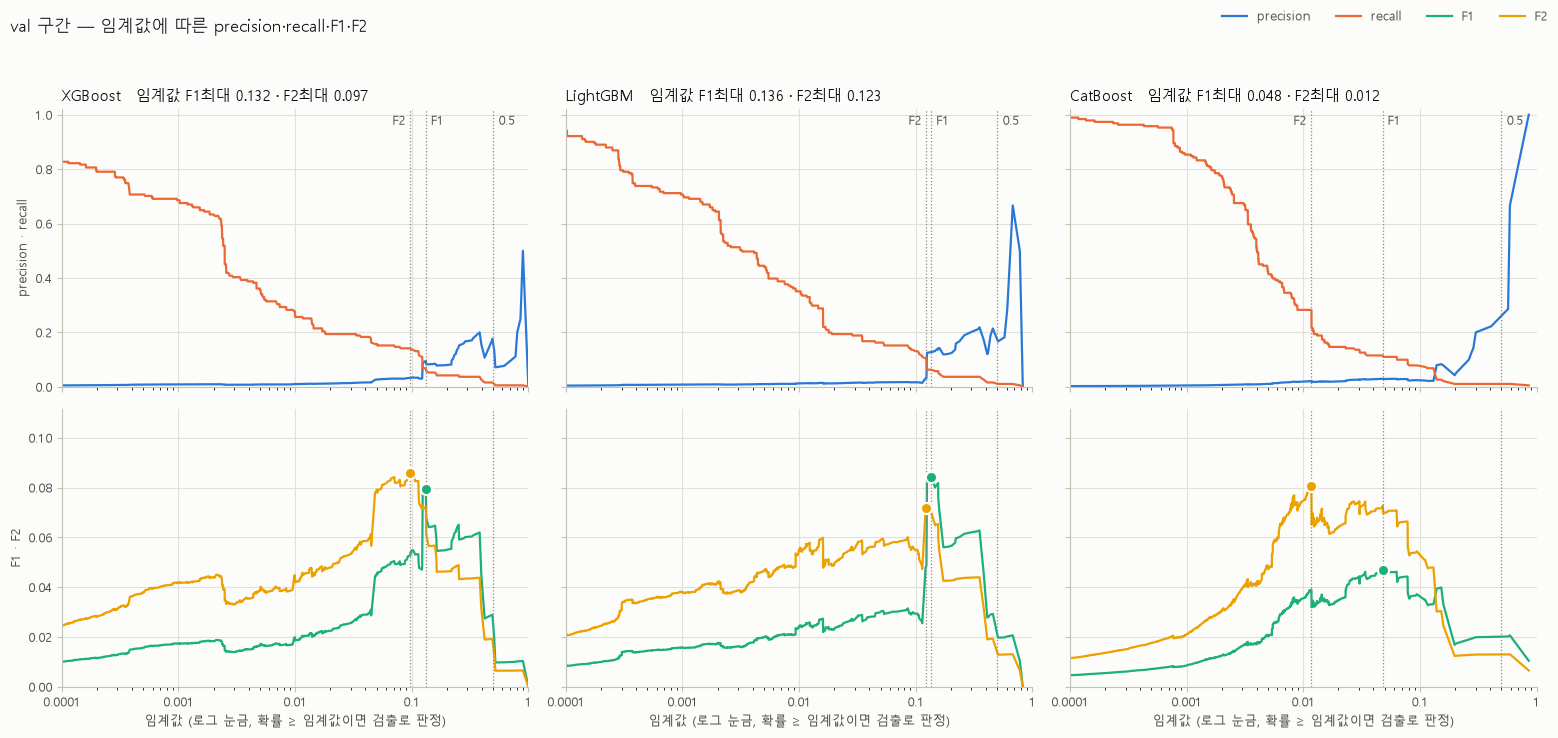

In [17]:
fig, axes = plt.subplots(2, len(models), figsize=(5.2 * len(models), 7.4),
                         sharex=True, sharey='row', facecolor=SURFACE)
f_max = 0
for j, name in enumerate(models):
    precision, recall, thr = precision_recall_curve(ys['val'], proba['val'][name])
    precision, recall = precision[:-1], recall[:-1]
    curves = {'precision': precision, 'recall': recall,
              'F1': fbeta_curve(precision, recall, 1), 'F2': fbeta_curve(precision, recall, 2)}
    f_max = max(f_max, curves['F1'].max(), curves['F2'].max())
    t1, t2 = thresholds[name]['F1최대'], thresholds[name]['F2최대']

    ax_top, ax_bot = axes[0, j], axes[1, j]
    for ax, keys in [(ax_top, ['precision', 'recall']), (ax_bot, ['F1', 'F2'])]:
        style_axes(ax)
        ax.set_xscale('log')
        for k in keys:
            ax.plot(thr, curves[k], color=METRIC_COLOR[k], linewidth=1.6)
        for t in {t1, t2, 0.5}:   # 세로 점선: 고른 임계값과 0.5
            ax.axvline(t, color=MUTED, linewidth=0.9, linestyle=':')

    # 아래 칸: F1·F2 곡선의 최고점 = 고른 임계값
    for t, k in [(t1, 'F1'), (t2, 'F2')]:
        ax_bot.plot(t, curves[k][np.searchsorted(thr, t)], 'o', markersize=8, color=METRIC_COLOR[k],
                    markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=5)

    # 위 칸 맨 위: 세로 점선 이름표 (작은 임계값은 선 왼쪽, 큰 임계값은 선 오른쪽)
    if t1 == t2:
        marks = [(t1, 'F1·F2', 'left')]
    else:
        (lo, lo_name), (hi, hi_name) = sorted([(t1, 'F1'), (t2, 'F2')])
        marks = [(lo, lo_name, 'right'), (hi, hi_name, 'left')]
    for t, text, ha in marks + [(0.5, '0.5', 'left')]:
        ax_top.text(t, 1.0, f' {text} ', ha=ha, va='top', color=INK2, fontsize=9)

    ax_top.set_title(f'{name}   임계값 F1최대 {t1:.3f} · F2최대 {t2:.3f}', loc='left', color=INK, fontsize=10.5)
    ax_bot.set_xlabel('임계값 (로그 눈금, 확률 ≥ 임계값이면 검출로 판정)', color=INK2, fontsize=9)

for ax in axes.flat:
    ax.set_xlim(1e-4, 1)
    ax.xaxis.set_major_formatter(PLAIN)
axes[0, 0].set_ylim(0, 1.02)
axes[1, 0].set_ylim(0, f_max * 1.3)
axes[0, 0].set_ylabel('precision · recall', color=INK2, fontsize=9)
axes[1, 0].set_ylabel('F1 · F2', color=INK2, fontsize=9)

legend_keys = [Line2D([], [], color=c, linewidth=1.6, label=k) for k, c in METRIC_COLOR.items()]
fig.legend(handles=legend_keys, loc='upper right', ncol=4, frameon=False, fontsize=9, labelcolor=INK2)
fig.suptitle('val 구간 — 임계값에 따른 precision·recall·F1·F2', x=0.01, ha='left', color=INK, fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.95))
FIGURES['val_threshold_curves.png'] = fig   # 10절에서 MLflow 에 올린다
plt.show()

### 9-2. test — PR 곡선

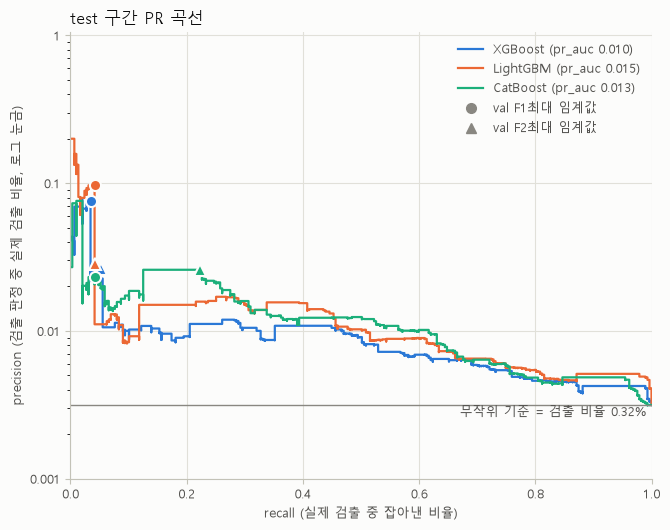

In [18]:
fig, ax = plt.subplots(figsize=(6.8, 5.4), facecolor=SURFACE)
style_axes(ax)
ax.set_yscale('log', nonpositive='mask')
pos_rate = ys['test'].mean()

for name in models:
    precision, recall, _ = precision_recall_curve(ys['test'], proba['test'][name])
    ap = average_precision_score(ys['test'], proba['test'][name])
    ax.plot(recall, precision, drawstyle='steps-post', color=MODEL_COLOR[name], linewidth=1.6,
            label=f'{name} (pr_auc {ap:.3f})')
    # val 에서 고른 임계값이 test 에서 찍힌 자리 (TP 가 0 이면 precision 0 이라 로그 눈금에 못 찍음)
    for rule, marker in [('F1최대', 'o'), ('F2최대', '^')]:
        row = metrics[(metrics['모델'] == name) & (metrics['구간'] == 'test')
                      & (metrics['임계값 규칙'] == rule)].iloc[0]
        if row['TP'] > 0:
            ax.plot(row['recall'], row['precision'], marker=marker, markersize=8, linestyle='none',
                    color=MODEL_COLOR[name], markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=5)

ax.axhline(pos_rate, color=MUTED, linewidth=1)
ax.text(0.99, pos_rate, f'무작위 기준 = 검출 비율 {pos_rate:.2%}', transform=ax.get_yaxis_transform(),
        ha='right', va='top', color=INK2, fontsize=9)

ax.set_xlim(0, 1)
ax.set_ylim(1e-3, 1.05)
ax.yaxis.set_major_formatter(PLAIN)
ax.set_xlabel('recall (실제 검출 중 잡아낸 비율)', color=INK2, fontsize=9)
ax.set_ylabel('precision (검출 판정 중 실제 검출 비율, 로그 눈금)', color=INK2, fontsize=9)
ax.set_title('test 구간 PR 곡선', loc='left', color=INK, fontsize=12)
marker_keys = [
    Line2D([], [], marker='o', linestyle='none', color=MUTED, markersize=7, label='val F1최대 임계값'),
    Line2D([], [], marker='^', linestyle='none', color=MUTED, markersize=7, label='val F2최대 임계값'),
]
ax.legend(handles=ax.get_legend_handles_labels()[0] + marker_keys,
          frameon=False, fontsize=9, labelcolor=INK2, loc='upper right')
fig.tight_layout()
FIGURES['test_pr_curve.png'] = fig   # 10절에서 MLflow 에 올린다
plt.show()

## 10. MLflow 에 기록

결과는 파일로 따로 저장하지 않고 MLflow 한곳에 모은다. 노트북을 다시 돌릴 때마다 새 기록이 쌓이고, 이전 실행·다음 단계 실험과 나란히 비교할 수 있다.

- **저장 위치**: `.env` 의 `AFLA_MLFLOW_URI`(`sqlite:///mlflow.db`, 상대경로). 노트북을 연 폴더마다 DB 가 따로 생기지 않도록 `.env` 가 있는 `리스테리아ML/` 기준으로 고정했다 → 기록 DB `리스테리아ML/mlflow.db`, 그림·표·예측 파일 `리스테리아ML/mlruns/`.
- **실험(experiment)**: `리스테리아_EXP1` — EXP/1 의 노트북(2_바로학습, 3_기상조인_후_학습)이 같은 실험에 기록해 서로 비교한다.

| 기록 단위 | run 이름 | params (조건) | metrics·artifacts (결과) |
|---|---|---|---|
| 부모 run 1개 | `2_바로학습` | 입력 파일·수정 시각, 분할 기간·건수·검출 수, 피처 목록, seed, 장치, 튜닝·불균형 처리·조기 종료 여부, 임계값 규칙 | 그림 2개(`figures/`), 지표 전체 표 `metrics.csv`, 시료별 예측 확률 `predictions.parquet`, 설정 전체 `config.json` |
| 자식 run 9개 (모델 3 × 임계값 규칙 3) | `2_바로학습 / XGBoost / F2최대` 처럼 `노트북 / 모델 / 규칙` | 입력 데이터 한 줄 설명 `input`, 모델, 임계값 규칙, 임계값, 장치, 하이퍼파라미터 전체(`hp.` 로 시작) | val·test 의 accuracy, precision, recall, f1, f2, roc_auc, pr_auc, TP, FN, FP, TN, 전체 건수 `n_total`, 실제 검출 `n_pos`, 예측 양성 수 `n_pred_pos` (이름 앞에 `val_`·`test_`), 임계값 `threshold`, 학습 시간 `fit_seconds` |

- 지표는 모두 0~1 사이 소수다(% 아님).
- **보는 법**: 터미널에서 아래 명령을 실행한 뒤 브라우저로 http://127.0.0.1:5000 을 연다. 실험 `리스테리아_EXP1` 에서 부모 run 을 펼치면 자식 run 9개가 한 표로 나오고, 칼럼(지표)을 골라 정렬·비교할 수 있다.

```
py -m mlflow ui --backend-store-uri "sqlite:///C:/Users/NT751/Desktop/천영진/리스테리아ML/mlflow.db"
```

In [19]:
# 기록할 내용 준비 — 부모 run 의 조건(params)·설정 전체·시료별 예측 확률
INPUT = f'LIMS {len(FEATURES)}칼럼'   # 입력 데이터 한 줄 설명 — MLflow 에서 run 을 구별하는 데 쓴다

def model_params(name, model):
    """하이퍼파라미터 전체 — CatBoost 는 기본값까지 풀어서, 나머지는 None = 라이브러리 기본값"""
    return model.get_all_params() if name == 'CatBoost' else model.get_params()

def file_mtime(path):
    return datetime.fromtimestamp(Path(path).stat().st_mtime).isoformat(timespec='seconds')

parent_params = {
    'input': INPUT,
    'data.X': X_path, 'data.X_mtime': file_mtime(X_path), 'data.X_shape': str(X.shape),
    'data.y': y_path, 'data.y_mtime': file_mtime(y_path),
    **{f'split.{r["구간"]}': f'{r["시작일"]}~{r["종료일"]} | {r["행 수"]:,}행 | 검출 {r["검출(1)"]:,}건'
       for r in split_summary.to_dict('records')},
    'features': json.dumps(FEATURES, ensure_ascii=False),
    'cat_features': json.dumps(CAT_COLS, ensure_ascii=False),
    'num_features': json.dumps(NUM_COLS, ensure_ascii=False),
    'n_features': len(FEATURES),
    'seed': SEED,
    **{f'device.{k}': v for k, v in DEVICE.items()},
    'tuning': '없음 (라이브러리 기본값)',
    'imbalance': '없음',
    'early_stopping': '없음',
    'threshold_rules': '0.5 / val F1최대 / val F2최대 (판정: 확률 >= 임계값)',
}

config = {   # config.json — 위 조건 + 고른 임계값·학습 시간·하이퍼파라미터 전체·라이브러리 버전
    'params': parent_params,
    'split': split_summary.astype({'시작일': str, '종료일': str}).to_dict('records'),
    'thresholds': thresholds,
    'fit_seconds': fit_seconds,
    'key_params': {name: key_params(name, m) for name, m in models.items()},
    'hyperparameters': {name: model_params(name, m) for name, m in models.items()},
    'libraries': {'python': sys.version.split()[0], 'pandas': pd.__version__, 'numpy': np.__version__,
                  'scikit-learn': sklearn.__version__, 'xgboost': xgb.__version__,
                  'lightgbm': lgb.__version__, 'catboost': cb.__version__, 'mlflow': mlflow.__version__},
}

pred_out = pd.concat([   # predictions.parquet — val·test 시료별 예측 확률
    pd.DataFrame({
        KEY_COL: X.loc[proba[s].index, KEY_COL].to_numpy(),
        '구간': s,
        DATE_COL: X.loc[proba[s].index, DATE_COL].to_numpy(),
        'y': ys[s].to_numpy(),
        **{f'p_{name}': proba[s][name].to_numpy() for name in models},
    })
    for s in ['val', 'test']
], ignore_index=True)

# metrics 표 칼럼 → MLflow metric 이름 (앞에 val_·test_ 가 붙는다)
METRIC_KEYS = {c: c for c in SCORE_COLS + ['TP', 'FN', 'FP', 'TN']}
METRIC_KEYS.update({'전체 건수': 'n_total', '실제 검출': 'n_pos', '예측 양성 수': 'n_pred_pos'})

print('부모 run params', len(parent_params), '개 | 예측 확률', pred_out.shape)

부모 run params 21 개 | 예측 확률 (178641, 7)


In [20]:
# MLflow 에 기록 — 부모 run 1개 + 자식 run 9개(모델 × 임계값 규칙)
NOTEBOOK = r'리스테리아ML\EXP\1\2_바로학습.ipynb'
STAGE = '1단계 — 정제만 한 데이터로 바로 학습 (튜닝·불균형 처리·기상 없음)'

with mlflow.start_run(run_name=RUN_NAME) as parent:
    mlflow.set_tags({'notebook': NOTEBOOK, 'stage': STAGE, 'mlflow.note.content': STAGE})
    mlflow.log_params(parent_params)
    for fname, fig in FIGURES.items():
        mlflow.log_figure(fig, f'figures/{fname}')
    mlflow.log_text('\ufeff' + metrics.to_csv(index=False), 'metrics.csv')   # \ufeff: 엑셀에서 한글 안 깨지게
    mlflow.log_dict(config, 'config.json')
    with tempfile.TemporaryDirectory() as tmp:   # 임시 폴더에 쓴 뒤 MLflow 로 옮긴다 (프로젝트 폴더에 안 남음)
        pred_path = Path(tmp) / 'predictions.parquet'
        pred_out.to_parquet(pred_path, index=False)
        mlflow.log_artifact(str(pred_path))

    for name, model in models.items():
        hp = {f'hp.{k}': v for k, v in model_params(name, model).items()}
        for rule, t in thresholds[name].items():
            with mlflow.start_run(run_name=f'{RUN_NAME} / {name} / {rule}', nested=True):
                mlflow.set_tags({'notebook': NOTEBOOK, 'stage': STAGE, 'model': name, 'threshold_rule': rule})
                mlflow.log_params({'input': INPUT, 'model': name, 'threshold_rule': rule, 'threshold': t,
                                   'device': DEVICE[name], **hp})
                values = {'threshold': t, 'fit_seconds': fit_seconds[name]}
                for s in ['val', 'test']:
                    row = metrics[(metrics['모델'] == name) & (metrics['구간'] == s)
                                  & (metrics['임계값 규칙'] == rule)].iloc[0]
                    values.update({f'{s}_{key}': float(row[col]) for col, key in METRIC_KEYS.items()})
                mlflow.log_metrics(values)

PARENT_RUN_ID = parent.info.run_id
print('기록 완료 — 부모 run', RUN_NAME, PARENT_RUN_ID)

기록 완료 — 부모 run 2_바로학습 2eba7aa25c4244bbaf36a7c136101a41


### 10-1. 기록 확인 — MLflow 에서 다시 읽어 온 test 결과

방금 기록한 자식 run 9개를 MLflow 에서 다시 읽어 온다. 나중에 다른 실행과 비교할 때도 같은 방식(`mlflow.search_runs`)으로 꺼내 쓸 수 있다. 지표는 0~1 소수다.

In [21]:
runs = mlflow.search_runs(
    experiment_names=[MLFLOW_EXPERIMENT],
    filter_string=f"tags.mlflow.parentRunId = '{PARENT_RUN_ID}'",
    order_by=['attributes.start_time ASC'],
)
view = {
    'tags.mlflow.runName': 'run', 'metrics.threshold': '임계값',
    'metrics.test_accuracy': 'accuracy', 'metrics.test_precision': 'precision', 'metrics.test_recall': 'recall',
    'metrics.test_f1': 'f1', 'metrics.test_f2': 'f2', 'metrics.test_roc_auc': 'roc_auc', 'metrics.test_pr_auc': 'pr_auc',
    'metrics.test_TP': 'TP', 'metrics.test_FN': 'FN', 'metrics.test_FP': 'FP', 'metrics.test_TN': 'TN',
    'metrics.test_n_total': '전체 건수', 'metrics.test_n_pred_pos': '예측 양성 수',
}
display(runs[list(view)].rename(columns=view)
        .astype({c: int for c in ['TP', 'FN', 'FP', 'TN', '전체 건수', '예측 양성 수']})
        .round({**{c: 4 for c in SCORE_COLS}, '임계값': 6}))

,run,임계값,accuracy,precision,recall,f1,f2,roc_auc,pr_auc,TP,FN,FP,TN,전체 건수,예측 양성 수
0,2_바로학습 / XGBoost / 0.5,0.500000,0.9967,0.0000,0.0000,0.0000,0.0000,0.7236,0.0102,0,287,18,90783,91088,18
1,2_바로학습 / XGBoost / F1최대,0.132155,0.9956,0.0763,0.0348,0.0478,0.0391,0.7236,0.0102,10,277,121,90680,91088,131
2,2_바로학습 / XGBoost / F2최대,0.097485,0.9909,0.0264,0.0523,0.0350,0.0437,0.7236,0.0102,15,272,554,90247,91088,569
3,2_바로학습 / LightGBM / 0.5,0.500000,0.9968,0.1538,0.0070,0.0133,0.0086,0.7651,0.0145,2,285,11,90790,91088,13
4,2_바로학습 / LightGBM / F1최대,0.135741,0.9958,0.0968,0.0418,0.0584,0.0472,0.7651,0.0145,12,275,112,90689,91088,124
5,2_바로학습 / LightGBM / F2최대,0.123407,0.9925,0.0284,0.0418,0.0338,0.0382,0.7651,0.0145,12,275,411,90390,91088,423
6,2_바로학습 / CatBoost / 0.5,0.500000,0.9968,0.0000,0.0000,0.0000,0.0000,0.7551,0.0132,0,287,0,90801,91088,0
7,2_바로학습 / CatBoost / F1최대,0.047964,0.9914,0.0232,0.0418,0.0298,0.0360,0.7551,0.0132,12,275,506,90295,91088,518
8,2_바로학습 / CatBoost / F2최대,0.011759,0.9712,0.0260,0.2230,0.0465,0.0885,0.7551,0.0132,64,223,2402,88399,91088,2466
